# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Shawn Miller**  
**Advanced Big Data and Data Mining (MSCS-634-B01)**

In this lab, I compare hierarchical clustering and DBSCAN using the Wine dataset.

## 1. Data Preparation

The Wine dataset has **178 samples, 13 numeric features, and 3 known wine types**. I checked the data with `head()`, `info()`, and `describe()`, then standardized it so features with larger values would not outweigh the others. The known wine types are only used to evaluate the results, not to train the models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_STATE = 42  # PCA uses a deterministic full solver; included for reproducibility.
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
wine = load_wine()
X_df = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target  # Used for evaluation only, never as an input to clustering.

print(f"Dataset shape: {X_df.shape[0]} rows x {X_df.shape[1]} features")
print(f"Known cultivars (used only for evaluation): {np.unique(y_true).tolist()}")
print("\nFirst five rows:")
display(X_df.head())

Dataset shape: 178 rows x 13 features
Known cultivars (used only for evaluation): [0, 1, 2]

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
print("Dataset info:")
X_df.info()
print("\nDescriptive statistics:")
display(X_df.describe().T.round(2))
print("\nTotal missing feature values:", int(X_df.isna().sum().sum()))
print("Duplicates:", int(X_df.duplicated().sum()))

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    floa

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00



Total missing feature values: 0
Duplicates: 0


### Scaling and visualization

I used `StandardScaler` for clustering and PCA to make 2D plots. The clustering still uses all 13 features, so the plots only show part of the data.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

scale_check = pd.DataFrame({
    "mean_after_scaling": X_scaled.mean(axis=0),
    "std_after_scaling": X_scaled.std(axis=0)
}, index=X_df.columns)
print("Scaled-feature check (first five):")
display(scale_check.head().round(3))

pca = PCA(n_components=2, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)
print("Explained variance by first two components:",
      [round(v, 3) for v in pca.explained_variance_ratio_])
print("Combined explained variance:", round(pca.explained_variance_ratio_.sum(), 3))

Scaled-feature check (first five):


,mean_after_scaling,std_after_scaling
alcohol,0.0,1.0
malic_acid,0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,-0.0,1.0
magnesium,-0.0,1.0


Explained variance by first two components: [np.float64(0.362), np.float64(0.192)]
Combined explained variance: 0.554


## 2. Measuring the Results

I used three scores:

- **Silhouette:** How well the clusters are separated (higher is better).
- **Homogeneity:** How well each cluster stays within one known wine type.
- **Completeness:** How well each wine type stays in one cluster.

DBSCAN labels noise as `-1`. I left noise out of its silhouette score but counted it as a separate group for homogeneity and completeness. Silhouette is shown as `NaN` when there are not enough clusters to calculate it. Because DBSCAN excludes noise from silhouette, its score is not a direct comparison with hierarchical clustering.

In [5]:
def summarize_labels(labels, model_name):
    """Return quality measures and counts for any clustering labels."""
    labels = np.asarray(labels)
    assigned = labels != -1
    non_noise = labels[assigned]
    clusters = len(np.unique(non_noise))
    coverage = float(assigned.mean())

    if model_name == "DBSCAN":
        score_X = X_scaled[assigned]
        score_labels = non_noise
    else:
        score_X = X_scaled
        score_labels = labels

    # A silhouette score is not defined for 0 or 1 clusters.
    valid = 2 <= len(np.unique(score_labels)) < len(score_labels)
    silhouette = float(silhouette_score(score_X, score_labels)) if valid else np.nan

    return {
        "clusters": clusters,
        "noise_points": int((~assigned).sum()),
        "coverage_pct": 100 * coverage,
        "silhouette": silhouette,
        "homogeneity_all": float(homogeneity_score(y_true, labels)),
        "completeness_all": float(completeness_score(y_true, labels)),
    }


def plot_pca_clusters(ax, labels, title):
    """Plot clusters on PCA axes, with DBSCAN's noise clearly marked."""
    labels = np.asarray(labels)
    unique_labels = sorted(set(labels) - {-1})
    colors = plt.get_cmap("tab10")
    for index, cluster_id in enumerate(unique_labels):
        mask = labels == cluster_id
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
                   s=30, alpha=0.8, color=colors(index % 10),
                   label=f"Cluster {cluster_id}")
    if -1 in labels:
        noise_mask = labels == -1
        ax.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
                   s=46, color="black", marker="x", linewidths=1.2,
                   label=f"Noise ({noise_mask.sum()})")
    ax.set(title=title,
           xlabel=f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% variance)",
           ylabel=f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% variance)")
    ax.legend(loc="best", fontsize=8, frameon=True)
    ax.grid(alpha=0.2)

## 3. Hierarchical Clustering

I used Ward linkage and tested **2 through 6 clusters** to see which grouping worked best.

In [6]:
hierarchical_labels = {}
hierarchical_rows = []
for n_clusters in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward").fit_predict(X_scaled)
    hierarchical_labels[n_clusters] = labels
    hierarchical_rows.append({"n_clusters": n_clusters, **summarize_labels(labels, "Hierarchical")})

hierarchical_results = pd.DataFrame(hierarchical_rows)
print("Hierarchical clustering results (all 178 samples assigned):")
display(hierarchical_results.round(3))

Hierarchical clustering results (all 178 samples assigned):


,n_clusters,clusters,noise_points,coverage_pct,silhouette,homogeneity_all,completeness_all
0,2,2,0,100.0,0.267,0.444,0.774
1,3,3,0,100.0,0.277,0.790,0.783
2,4,4,0,100.0,0.226,0.790,0.649
3,5,5,0,100.0,0.187,0.811,0.576
4,6,6,0,100.0,0.180,0.835,0.553


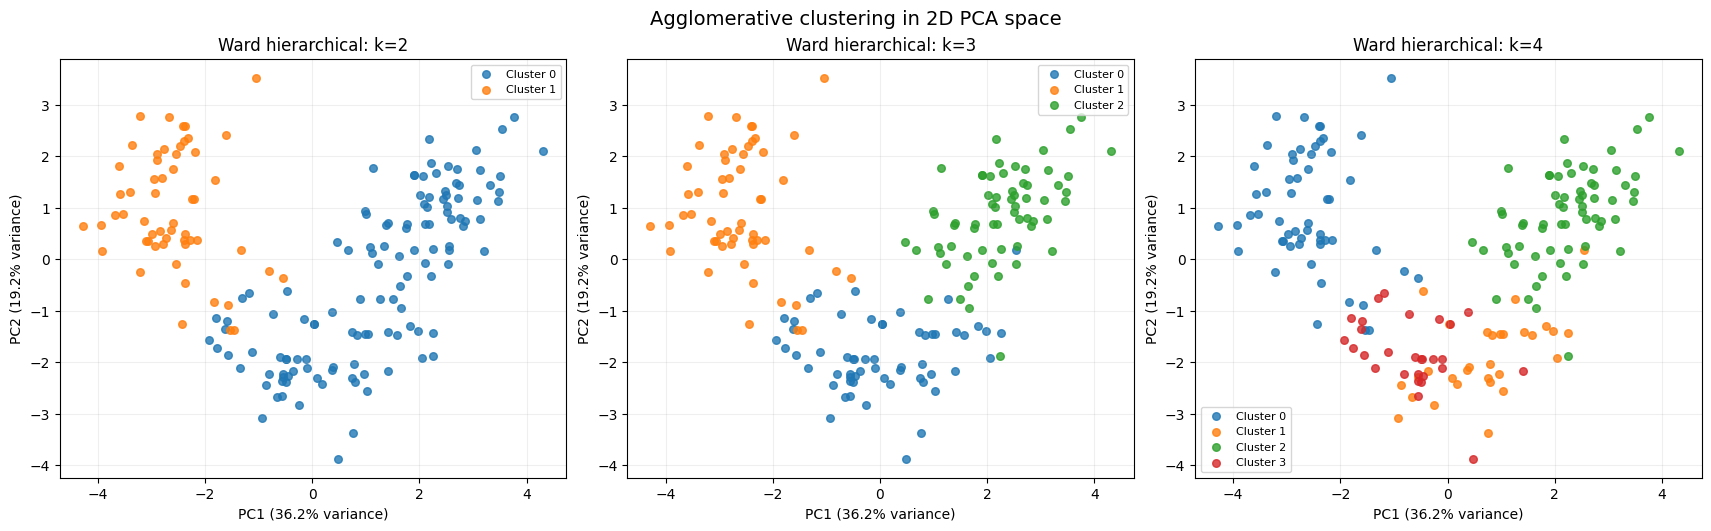

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
for ax, n_clusters in zip(axes, [2, 3, 4]):
    plot_pca_clusters(ax, hierarchical_labels[n_clusters], f"Ward hierarchical: k={n_clusters}")
fig.suptitle("Agglomerative clustering in 2D PCA space", fontsize=14)
plt.show()

### Dendrogram

The dendrogram shows which wines join together as clusters grow. Higher branches mean the groups were farther apart. The dashed line shows a possible cut for three clusters.

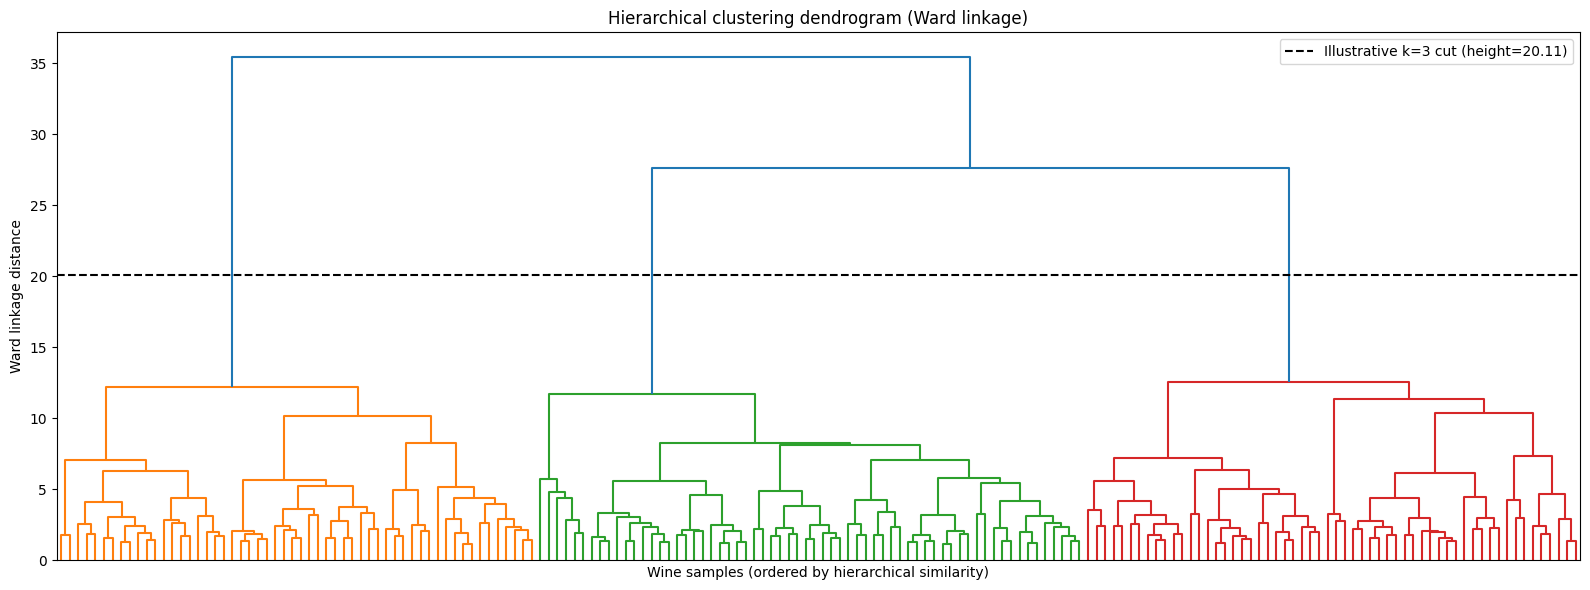

Best hierarchical silhouette among tested k values: k=3, silhouette=0.277


In [8]:
Z = linkage(X_scaled, method="ward")
# These are the consecutive merger heights bracketing a 3-cluster cut.
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

fig, ax = plt.subplots(figsize=(16, 6))
dendrogram(Z, no_labels=True, color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, color="black", linestyle="--", linewidth=1.5,
           label=f"Illustrative k=3 cut (height={cut_height:.2f})")
ax.set(title="Hierarchical clustering dendrogram (Ward linkage)",
       xlabel="Wine samples (ordered by hierarchical similarity)",
       ylabel="Ward linkage distance")
ax.legend()
plt.tight_layout()
plt.show()

best_hierarchical = hierarchical_results.loc[
    hierarchical_results["silhouette"].idxmax()
]
print("Best hierarchical silhouette among tested k values:",
      f"k={int(best_hierarchical['n_clusters'])}, "
      f"silhouette={best_hierarchical['silhouette']:.3f}")

**What I found:** Three clusters worked best out of the settings I tested, with a **0.277 silhouette**, **0.790 homogeneity**, and **0.783 completeness**. The dendrogram helps show how those groups form. Using more than three clusters lowered the silhouette score.

## 4. DBSCAN Clustering

DBSCAN groups nearby points and marks isolated ones as noise. I tested **24 combinations** of `eps` (distance) and `min_samples` (points needed to form a dense area).

In [9]:
eps_values = [1.6, 1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]
min_samples_values = [3, 5, 8]

dbscan_labels = {}
dbscan_rows = []
for eps in eps_values:
    for min_samples in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        dbscan_labels[(eps, min_samples)] = labels
        dbscan_rows.append({
            "eps": eps, "min_samples": min_samples,
            **summarize_labels(labels, "DBSCAN")
        })

dbscan_results = pd.DataFrame(dbscan_rows)
print("DBSCAN parameter sweep. NaN silhouette = not enough non-noise clusters:")
display(dbscan_results.round(3))

DBSCAN parameter sweep. NaN silhouette = not enough non-noise clusters:


,eps,min_samples,clusters,noise_points,coverage_pct,silhouette,homogeneity_all,completeness_all
0,1.6,3,10,124,30.337,0.255,0.323,0.280
1,1.6,5,3,162,8.989,0.502,0.100,0.271
2,1.6,8,0,178,0.000,NaN,0.000,1.000
3,1.8,3,8,90,49.438,0.312,0.532,0.375
4,1.8,5,7,118,33.708,0.246,0.354,0.307
5,1.8,8,1,170,4.494,NaN,0.057,0.337
6,2.0,3,5,64,64.045,0.211,0.442,0.372
7,2.0,5,5,85,52.247,0.240,0.362,0.325
8,2.0,8,3,117,34.270,0.436,0.390,0.469
9,2.2,3,3,44,75.281,0.073,0.486,0.481


### Changing `eps`

With `min_samples=5`, a smaller `eps` leaves more noise points. A larger `eps` connects more points but can merge clusters. Black × marks show noise on the plots.

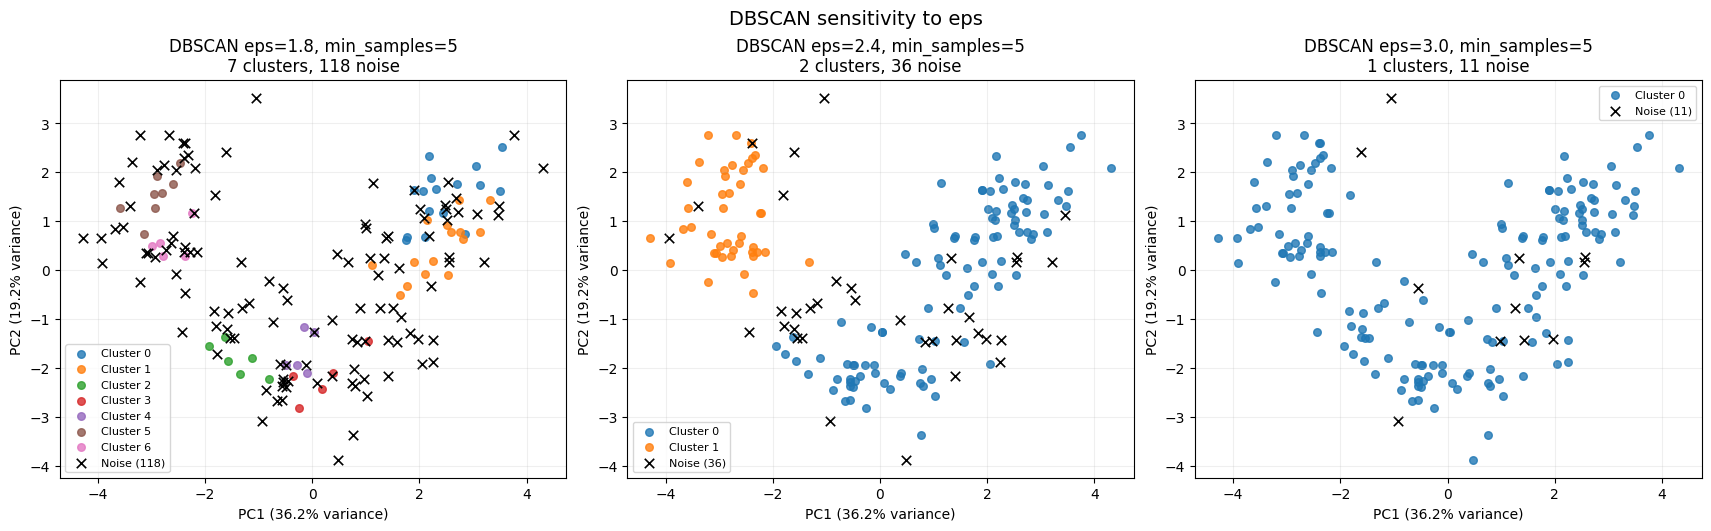

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
for ax, eps in zip(axes, [1.8, 2.4, 3.0]):
    labels = dbscan_labels[(eps, 5)]
    noise = int((labels == -1).sum())
    groups = len(set(labels) - {-1})
    plot_pca_clusters(ax, labels,
                      f"DBSCAN eps={eps}, min_samples=5\n{groups} clusters, {noise} noise")
fig.suptitle("DBSCAN sensitivity to eps", fontsize=14)
plt.show()

### Changing `min_samples`

With `eps=2.4`, increasing `min_samples` makes it harder for points to form a cluster and generally creates more noise.

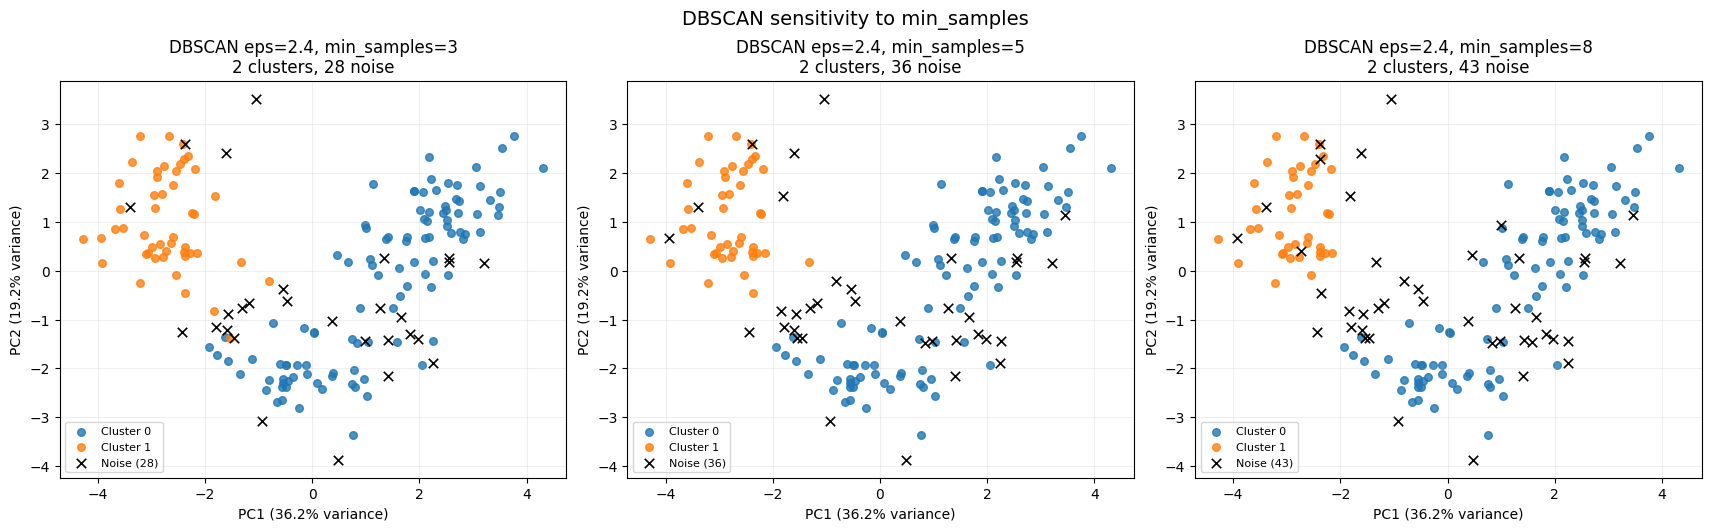

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
for ax, min_samples in zip(axes, [3, 5, 8]):
    labels = dbscan_labels[(2.4, min_samples)]
    noise = int((labels == -1).sum())
    groups = len(set(labels) - {-1})
    plot_pca_clusters(ax, labels,
                      f"DBSCAN eps=2.4, min_samples={min_samples}\n{groups} clusters, {noise} noise")
fig.suptitle("DBSCAN sensitivity to min_samples", fontsize=14)
plt.show()

### Parameter summary

These heatmaps show how the number of clusters and noise points changes with different settings.

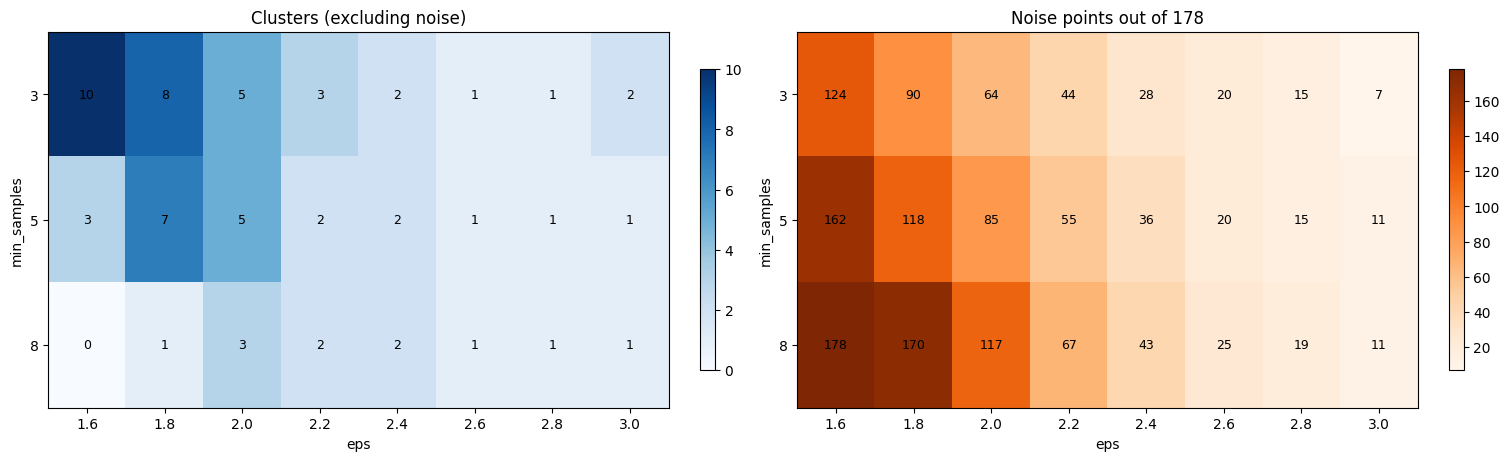

In [12]:
cluster_grid = dbscan_results.pivot(index="min_samples", columns="eps", values="clusters")
noise_grid = dbscan_results.pivot(index="min_samples", columns="eps", values="noise_points")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
for ax, grid, label, cmap, fmt in [
    (axes[0], cluster_grid, "Clusters (excluding noise)", "Blues", "d"),
    (axes[1], noise_grid, "Noise points out of 178", "Oranges", "d")
]:
    plot = ax.imshow(grid.to_numpy(), aspect="auto", cmap=cmap)
    ax.set_xticks(range(len(grid.columns)), [f"{v:.1f}" for v in grid.columns])
    ax.set_yticks(range(len(grid.index)), [str(v) for v in grid.index])
    ax.set(xlabel="eps", ylabel="min_samples", title=label)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{int(grid.iloc[i, j])}", ha="center", va="center", fontsize=9)
    fig.colorbar(plot, ax=ax, shrink=0.8)
plt.show()

### DBSCAN setting used for comparison

I chose **`eps=2.4` and `min_samples=5`** because the results were easy to compare: **2 clusters and 36 noise points** (**79.8% coverage**). This does not mean it was the best match for the three known wine types.

In [13]:
chosen_eps = 2.4
chosen_min_samples = 5
chosen_dbscan_labels = dbscan_labels[(chosen_eps, chosen_min_samples)]
chosen_dbscan_metrics = summarize_labels(chosen_dbscan_labels, "DBSCAN")
print("Selected DBSCAN results:")
display(pd.DataFrame([chosen_dbscan_metrics], index=["eps=2.4, min_samples=5"]).round(3))
print("\nDBSCAN cluster sizes, including noise (-1):")
display(pd.Series(chosen_dbscan_labels, name="DBSCAN cluster").value_counts().sort_index().to_frame("samples"))

Selected DBSCAN results:


,clusters,noise_points,coverage_pct,silhouette,homogeneity_all,completeness_all
"eps=2.4, min_samples=5",2,36,79.775,0.327,0.504,0.552



DBSCAN cluster sizes, including noise (-1):


,samples
DBSCAN cluster,
-1,36
0,99
1,43


## 5. Comparing the Methods

I compared hierarchical clustering with **3 clusters** to DBSCAN with **`eps=2.4` and `min_samples=5`**. Both used the same scaled data, but DBSCAN can leave points out as noise.

In [14]:
hierarchical_3 = hierarchical_labels[3]
hierarchical_3_metrics = summarize_labels(hierarchical_3, "Hierarchical")

comparison = pd.DataFrame([
    {"method": "Hierarchical (Ward, k=3)", **hierarchical_3_metrics},
    {"method": "DBSCAN (eps=2.4, min_samples=5)", **chosen_dbscan_metrics}
]).set_index("method")
print("Side-by-side results:")
display(comparison.round(3))
print("\nNOTE: DBSCAN silhouette excludes noise; hierarchical silhouette includes all samples.")
print("Homogeneity/completeness include DBSCAN noise as a separate predicted label.")

print("\nKnown cultivar vs. hierarchical cluster (evaluation only):")
display(pd.crosstab(pd.Series(y_true, name="cultivar"),
                    pd.Series(hierarchical_3, name="hierarchical_cluster")))
print("\nKnown cultivar vs. DBSCAN cluster (evaluation only; -1 is noise):")
display(pd.crosstab(pd.Series(y_true, name="cultivar"),
                    pd.Series(chosen_dbscan_labels, name="dbscan_cluster")))

Side-by-side results:


,clusters,noise_points,coverage_pct,silhouette,homogeneity_all,completeness_all
method,,,,,,
"Hierarchical (Ward, k=3)",3,0,100.000,0.277,0.790,0.783
"DBSCAN (eps=2.4, min_samples=5)",2,36,79.775,0.327,0.504,0.552



NOTE: DBSCAN silhouette excludes noise; hierarchical silhouette includes all samples.
Homogeneity/completeness include DBSCAN noise as a separate predicted label.

Known cultivar vs. hierarchical cluster (evaluation only):


hierarchical_cluster,0,1,2
cultivar,,,
0,0,0,59
1,58,8,5
2,0,48,0



Known cultivar vs. DBSCAN cluster (evaluation only; -1 is noise):


dbscan_cluster,-1,0,1
cultivar,,,
0,2,57,0
1,28,42,1
2,6,0,42


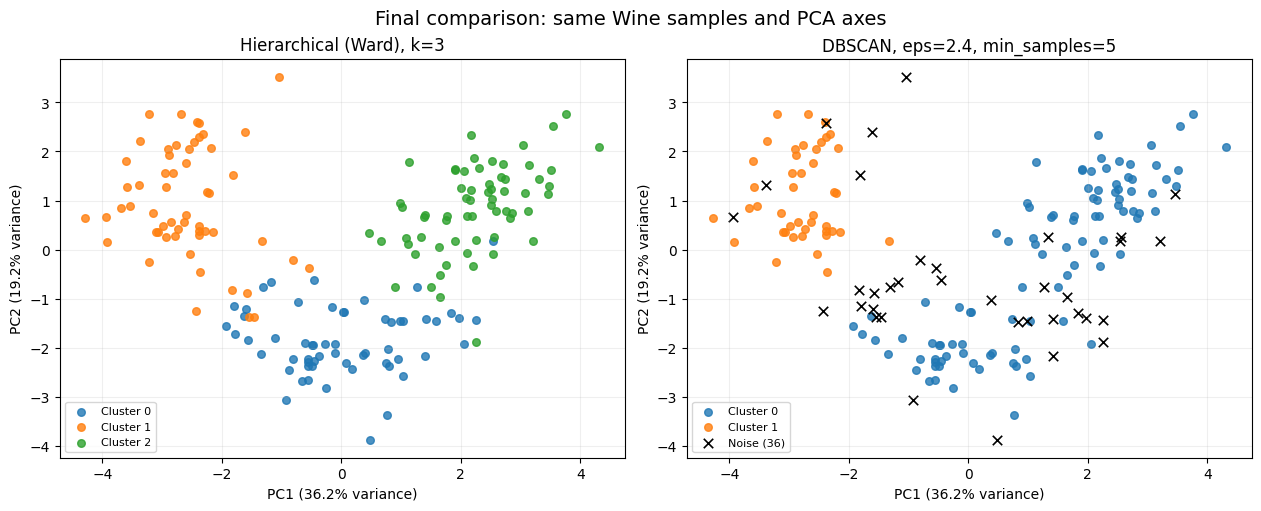

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), constrained_layout=True)
plot_pca_clusters(axes[0], hierarchical_3, "Hierarchical (Ward), k=3")
plot_pca_clusters(axes[1], chosen_dbscan_labels,
                  "DBSCAN, eps=2.4, min_samples=5")
fig.suptitle("Final comparison: same Wine samples and PCA axes", fontsize=14)
plt.show()

### Findings and Reflection

**Hierarchical clustering** grouped all **178 wines**. Its best result was **3 clusters** with a **0.277 silhouette**, **0.790 homogeneity**, and **0.783 completeness**. The dendrogram made it easier to understand how groups connected. The downside is that I have to choose the number of clusters, and it does not flag noise.

**DBSCAN** made **2 clusters** and marked **36 wines as noise** at `eps=2.4` and `min_samples=5`. Its silhouette was **0.327** on the non-noise points, with **0.504 homogeneity** and **0.552 completeness** when noise was counted as a separate group. It is useful for finding isolated points, but small parameter changes affected the results a lot. Its higher silhouette does **not** mean it worked better, since 36 points were excluded from that score.

**What changed with the settings:** Hierarchical clustering had a lower silhouette when I went beyond three clusters. For DBSCAN, smaller `eps` values left more noise, larger values merged groups, and higher `min_samples` usually added more noise.

**Overall:** Hierarchical clustering matched the Wine dataset's main groups better. DBSCAN was more helpful for spotting noise. I would use hierarchical clustering when I need clear groups for every sample, and DBSCAN when finding unusual points matters. The PCA graphs helped me see the patterns, but they only show two of the 13 feature dimensions.